# Energy-RAG: Analyse & Evaluation

Dieses Notebook dokumentiert die methodischen Entscheidungen des Projekts mit Zahlen:

1. **Korpus & Chunking** – wie viele Seiten/Chunks, wie lang sind sie in Tokens?
2. **Zwei Fehler des Ausgangsstands** – abgeschnittene Chunks und falsche Score-Umrechnung
3. **Retrieval-Evaluation** – fünf Konfigurationen auf 34 handannotierten Fragen
4. **Fehleranalyse** – welche Fragen bleiben schwierig?
5. **Beispiel** – Antwort mit Quellenangaben

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energy_rag.chunking import chunk_pages
from energy_rag.config import PROJECT_ROOT, Settings
from energy_rag.evaluation import load_testset
from energy_rag.ingestion import load_pdfs

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 90)
IMG = PROJECT_ROOT / 'docs' / 'images'
IMG.mkdir(parents=True, exist_ok=True)
settings = Settings()

## 1. Korpus und Chunking

In [2]:
pages = load_pdfs(settings.data_dir)
corpus = pd.DataFrame([{'Dokument': p.source, 'Zeichen': len(p.text)} for p in pages])
corpus.groupby('Dokument').agg(Seiten=('Zeichen', 'size'), Zeichen=('Zeichen', 'sum'))

,Seiten,Zeichen
Dokument,,
2021-02-17_cc_08-2021_transformation_stromerzeugung_2050_0.pdf,252,523103
DE2024_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf,51,167066
MonitoringberichtEnergie2024.pdf,340,530162


In [3]:
from transformers import AutoTokenizer

configs = {
    'Ausgangsstand (1000/200)': (1000, 200, 'sentence-transformers/all-MiniLM-L6-v2', 256),
    'Neu (800/150)': (800, 150, 'intfloat/multilingual-e5-small', 512),
}
rows = []
for name, (size, overlap, model, max_len) in configs.items():
    chunks = chunk_pages(pages, size, overlap)
    tok = AutoTokenizer.from_pretrained(model)
    n_tokens = np.array([len(tok(c.text)['input_ids']) for c in chunks])
    rows.append({
        'Konfiguration': name, 'Modell': model.split('/')[-1], 'Chunks': len(chunks),
        'Ø Tokens': round(n_tokens.mean()), 'Max. Tokens Modell': max_len,
        'Anteil abgeschnitten': f'{(n_tokens > max_len).mean():.0%}',
    })
pd.DataFrame(rows).set_index('Konfiguration')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (581 > 512). Running this sequence through the model will result in indexing errors


,Modell,Chunks,Ø Tokens,Max. Tokens Modell,Anteil abgeschnitten
Konfiguration,,,,,
Ausgangsstand (1000/200),all-MiniLM-L6-v2,1852,263,256,63%
Neu (800/150),multilingual-e5-small,2207,151,512,0%


**Fehler 1 – stilles Abschneiden:** `all-MiniLM-L6-v2` verarbeitet höchstens 256 Wordpiece-Tokens. Deutscher Fachtext zerfällt im englischen Vokabular in sehr viele Teilwörter, sodass ein Großteil der 1000-Zeichen-Chunks abgeschnitten wurde – der Rest des Chunks war für die Suche unsichtbar. Das multilinguale E5-Modell hat ein passendes Vokabular und 512 Tokens Kontext.

## 2. Fehler 2 – L2-Distanz als Kosinus interpretiert

In [4]:
# Chroma nutzt standardmäßig die quadrierte L2-Distanz. Für normierte Vektoren gilt
# d = 2 - 2·cos  →  der alte Code rechnete 'similarity = 1 - d = 2·cos - 1'.
cos = np.linspace(0, 1, 6)
pd.DataFrame({'echte Kosinus-Ähnlichkeit': cos, 'alter Score (1 - L2²)': 2 * cos - 1}).round(2)

,echte Kosinus-Ähnlichkeit,alter Score (1 - L2²)
0,0.0,-1.0
1,0.2,-0.6
2,0.4,-0.2
3,0.6,0.2
4,0.8,0.6
5,1.0,1.0


Alle Treffer mit einer Kosinus-Ähnlichkeit unter 0,5 bekamen einen **negativen** Score und wurden vom Filter `score >= 0` verworfen – deshalb lieferte die Beispielanfrage im alten Notebook nur 1 statt 5 Treffer. Lösung: Collection mit `space='cosine'`.

## 3. Retrieval-Evaluation

Testset: 34 beantwortbare Fragen (12 ISE, 14 Monitoringbericht, 8 UBA), in Alltagssprache formuliert, mit Belegseiten, die reproduzierbar aus Evidenz-Mustern bestimmt wurden (`energy-rag annotate`). Ein Treffer zählt, wenn ein Chunk von einer Belegseite des richtigen Dokuments stammt.

In [5]:
results = json.loads((PROJECT_ROOT / 'docs/results/retrieval_metrics.json').read_text(encoding='utf-8'))
metrics = pd.DataFrame([{'Konfiguration': r['label'], **r['metrics'],
                         'Latenz (ms)': round(r['mean_latency_ms'])} for r in results]).set_index('Konfiguration')
metrics.style.format({c: '{:.2f}' for c in metrics.columns if c != 'Latenz (ms)'})

,Hit@1,Hit@3,Hit@5,Hit@10,MRR@10,Latenz (ms)
Konfiguration,,,,,,
"Ausgangsstand: MiniLM (englisch), 1000/200, dense",0.09,0.18,0.18,0.29,0.14,22
"Multilinguales E5, 800/150, dense",0.41,0.65,0.76,0.82,0.56,36
"BM25 (lexikalisch), 800/150",0.29,0.47,0.53,0.76,0.42,4
Hybrid E5 + BM25 (RRF),0.35,0.62,0.76,0.88,0.53,40
Hybrid + Cross-Encoder-Reranking,0.50,0.79,0.88,0.97,0.65,5295


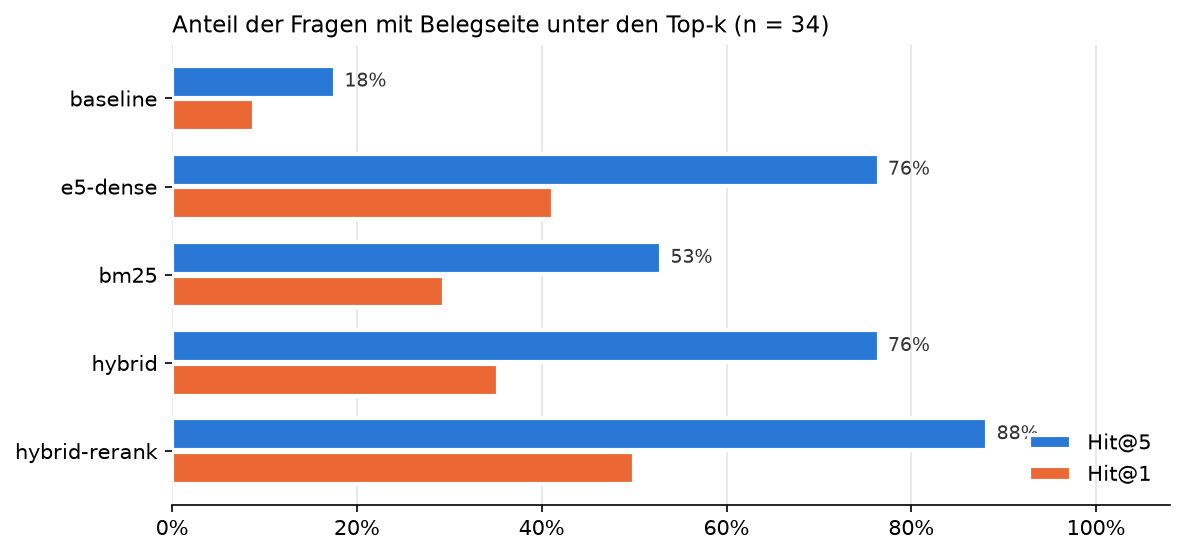

In [6]:
labels = [r['experiment'] for r in results]
hit1 = [r['metrics']['Hit@1'] for r in results]
hit5 = [r['metrics']['Hit@5'] for r in results]
y = np.arange(len(labels))[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8), dpi=150)
ax.barh(y + 0.19, hit5, height=0.36, color='#2a78d6', label='Hit@5', edgecolor='white', linewidth=2)
ax.barh(y - 0.19, hit1, height=0.36, color='#eb6834', label='Hit@1', edgecolor='white', linewidth=2)
for yi, v in zip(y, hit5):
    ax.text(v + 0.01, yi + 0.19, f'{v:.0%}', va='center', fontsize=9, color='#333')
ax.set_yticks(y, labels)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.grid(axis='x', color='#e5e5e5'); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
ax.set_title('Anteil der Fragen mit Belegseite unter den Top-k (n = 34)', loc='left', fontsize=11)
ax.legend(frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig(IMG / 'retrieval_comparison.png', bbox_inches='tight')
plt.show()

## 4. Fehleranalyse je Frage

In [7]:
items = {i.id: i for i in load_testset(PROJECT_ROOT / 'data/eval/testset.jsonl') if i.answerable}
ranks = pd.DataFrame({r['experiment']: r['ranks'] for r in results})
ranks.insert(0, 'Frage', [items[i].question for i in ranks.index])
best = results[-1]['experiment']
print('Rang der ersten Belegseite (leer = nicht in Top-10)')
ranks.sort_values(best, na_position='first').head(12)

Rang der ersten Belegseite (leer = nicht in Top-10)


,Frage,baseline,e5-dense,bm25,hybrid,hybrid-rerank
ise-06,Welche Preisspanne für Batteriespeicher pro kWh Speicherkapazität legt die ISE-Studie ...,NaN,NaN,NaN,9.0,NaN
ise-04,Was würde Strom aus einem 2024 neu gebauten Atomkraftwerk kosten?,NaN,1.0,2.0,1.0,1.0
ise-09,Warum sind die Ergebnisse der aktuellen Stromgestehungskosten-Studie höher als in früh...,NaN,2.0,2.0,1.0,1.0
mon-04,Wie konzentriert ist der Markt der Stromerzeugung – welchen Marktanteil hatten die fün...,NaN,2.0,1.0,1.0,1.0
mon-05,Wie stark sind die Netzentgelte für Haushalte 2024 gestiegen?,8.0,1.0,1.0,1.0,1.0
mon-01,Wie viel Strom wurde 2023 in Deutschland netto erzeugt?,NaN,2.0,6.0,2.0,1.0
ise-12,"Welche Betriebskosten erreichen GuD-Kraftwerke, wenn ihre Wärme in Fernwärmenetzen gen...",1.0,1.0,1.0,1.0,1.0
ise-11,Was kostet Freiflächen-Photovoltaik in sonnenreichen Regionen mit einer Einstrahlung v...,NaN,1.0,2.0,1.0,1.0
ise-10,Wie werden die Diskontierungssätze für die einzelnen Technologien festgelegt?,NaN,7.0,1.0,2.0,1.0
mon-14,Wie hoch war das durchschnittliche Gas-Netzentgelt für Haushaltskunden zum 1. April 2024?,6.0,1.0,1.0,1.0,1.0


In [8]:
by_doc = ranks.assign(Dokument=[i.split('-')[0] for i in ranks.index])
(by_doc.drop(columns='Frage').groupby('Dokument')
      .agg(lambda s: (s.fillna(99) <= 5).mean()).round(2)
      .rename(index={'ise': 'Fraunhofer ISE', 'mon': 'Monitoringbericht', 'uba': 'UBA 2050'}))

,baseline,e5-dense,bm25,hybrid,hybrid-rerank
Dokument,,,,,
Fraunhofer ISE,0.08,0.58,0.50,0.67,0.83
Monitoringbericht,0.21,0.93,0.50,0.79,1.00
UBA 2050,0.25,0.75,0.62,0.88,0.75


## 5. Beispiel: Antwort mit Quellenangaben

In [9]:
from energy_rag.pipeline import RAGPipeline

pipeline = RAGPipeline.from_settings(settings)
answer = pipeline.ask('Wie teuer ist Strom aus neuen Windkraftanlagen an Land?')
print(f'Generator: {answer.model}\n')
print(answer.text, '\n')
for i, s in enumerate(answer.sources, 1):
    print(f'[{i}] {s.chunk.citation}  (Score {s.score:.2f})')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3434.88it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5050.35it/s]

Kein ANTHROPIC_API_KEY gesetzt – nutze extraktiven Fallback ohne LLM.


Generator: extractive

Relevanteste Fundstellen (ohne LLM):
„liegen über 12 €Cent/kWh und GuD-Kraftwerke mit Wärmeausspeisung über 9 €Cent/kWh. Die Stromgestehungskosten von Onshore-Windkraftanlagen und PV-Anlagen stabilisieren sich hingegen im Bereich zwischen 5 und 10 €Cent/kWh.“ [1]
„(WEA) liegen im Jahr 2024 zwischen 4,3 und 9,2 €Cent/kWh, basierend auf spezifischen Anlagenkosten von 1300 bis 1900 EUR/kW. Damit sind PV-Freiflächenanlagen und Onshore-Windenergieanlagen nicht nur unter den erneuerbaren Energien, sondern unter allen Kraftwerksarten die kostengünstigsten Technologien in Deutschland. Mit bis zu 4500 Volllaststunden erzielen Offshore-Windanlagen …“ [2] 

[1] DE2024_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf, S. 35  (Score 1.89)
[2] DE2024_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf, S. 5  (Score 0.77)
[3] DE2024_ISE_Studie_Stromgestehungskosten_Erneuerbare_Energien.pdf, S. 26  (Score 0.56)
[4] DE2024_ISE_Studie_Stromgestehungskosten_Erneuerba

Ohne `ANTHROPIC_API_KEY` zeigt die Pipeline die besten Fundstellen extraktiv an; mit Key formuliert Claude eine Antwort, die jede Aussage mit `[Nr]` belegt.